# Concrete Column
**ACI 318-19 · ASCE 7-22 LRFD load combinations**

Rectangular tied, rectangular spiral, circular spiral, or circular tied column.
Builds the P–M interaction diagram about each axis by strain compatibility
(φ per ACI Table 21.2.2, capped at φPn,max), magnifies moments for nonsway slenderness
(ACI 6.6.4), checks biaxial bending (Bresler reciprocal load method), reinforcement
limits, bar spacing, and tie or spiral detailing.

**How to use:** Run the **Engine** cell once, edit the form fields below, and run **Runtime → Run all** (`Ctrl+F9` / `⌘F9`).

> Design aid only. A licensed engineer must verify all inputs and results.

In [1]:
#@title Engine — run this cell first (embedded structcalc library) { display-mode: "form" }
# Unpacks the embedded structcalc library and imports it (no pip install or Drive mount needed).
# Source: structural-calculations (lib/structcalc). Rebuild notebooks with: python build.py
import base64 as _b64, io as _io, os as _os, sys as _sys, tempfile as _tf, zipfile as _zf
_ZIP = (
    "..."
)
_dir = _os.path.join(_tf.gettempdir(), "structcalc_ace3f170d5")
if not _os.path.isdir(_os.path.join(_dir, "structcalc")):
    _zf.ZipFile(_io.BytesIO(_b64.b64decode(_ZIP))).extractall(_dir)
for _m in [m for m in _sys.modules if m == "structcalc" or m.startswith("structcalc.")]:
    del _sys.modules[_m]
if _dir not in _sys.path:
    _sys.path.insert(0, _dir)
import structcalc
print(f"structcalc {structcalc.__version__} ready (build ace3f170d5)")

structcalc 0.1.0 ready (build ace3f170d5)


In [2]:
#@title 1. Section and materials
shape = "Rectangular tied"  #@param ["Rectangular tied", "Rectangular spiral", "Circular spiral", "Circular tied"]
b = 16.0  #@param {type:"number"}
h = 16.0  #@param {type:"number"}
D = 18.0  #@param {type:"number"}
#@markdown Dimensions in **in**: `b` along x, `h` along y (rectangular). `D` = diameter (circular).
fc = 4000.0  #@param {type:"number"}
fy = 60000.0  #@param {type:"number"}
fyt = 60000.0  #@param {type:"number"}
#@markdown Strengths in **psi**.

In [3]:
#@title 2. Reinforcement
bar = 9  #@param [5, 6, 7, 8, 9, 10, 11, 14, 18] {type:"raw"}
nx = 3  #@param {type:"integer"}
ny = 3  #@param {type:"integer"}
n_circ = 8  #@param {type:"integer"}
cover = 1.5  #@param {type:"number"}
tie = 3  #@param [3, 4, 5] {type:"raw"}
s_tie = 16.0  #@param {type:"number"}
agg = 0.75  #@param {type:"number"}
#@markdown Rectangular: `nx` = bars on each face parallel to x (corners included), `ny` = bars on each face parallel to y (corners included).
#@markdown Circular: `n_circ` = total bars. Cover = clear cover to tie or spiral (in). `s_tie` = tie spacing or spiral pitch (in).

In [4]:
#@title 3. Length and slenderness (nonsway frame)
lu = 12.0  #@param {type:"number"}
kx = 1.0  #@param {type:"number"}
ky = 1.0  #@param {type:"number"}
ei_method = "(0.2 Ec Ig + Es Ise)/(1+beta_dns)"  #@param ["(0.2 Ec Ig + Es Ise)/(1+beta_dns)", "0.4 Ec Ig/(1+beta_dns)"]
#@markdown `lu` = unsupported length (ft). `kx` for bending about x, `ky` for bending about y (k <= 1.0 for a nonsway frame).

In [5]:
#@title 4. Service loads by case: "P, Mx_top, Mx_bot, My_top, My_bot"
#@markdown P in **kip** (compression +), moments in **kip-ft**. End moments with the same sign = single curvature. Leave a case blank if it is zero.
loads_D = "200, 30, -15, 10, 10"  #@param {type:"string"}
loads_L = "120, 20, -10, 5, 5"  #@param {type:"string"}
loads_Lr = ""  #@param {type:"string"}
loads_S = ""  #@param {type:"string"}
loads_W = ""  #@param {type:"string"}
loads_E = ""  #@param {type:"string"}

In [6]:
#@title 5. Calculate
from structcalc.calcs import concrete_column

case_loads = {c: concrete_column.parse_case(t) for c, t in
              {"D": loads_D, "L": loads_L, "Lr": loads_Lr, "S": loads_S,
               "W": loads_W, "E": loads_E}.items()}
out = concrete_column.run(
    shape=shape, b=b, h=h, D=D, fc=fc, fy=fy, fyt=fyt, bar=bar, nx=nx, ny=ny,
    n_circ=n_circ, cover=cover, tie=tie, s_tie=s_tie, agg=agg, lu=lu, kx=kx, ky=ky,
    ei_method=ei_method, case_loads=case_loads,
)
out["report"].show()

Shape,Rectangular tied,
Size,"b = 16 (x), h = 16 (y)",in
f'c / fy,4000 / 60000,psi
Bars,"8 #9 (3 per x-face, 3 per y-face)",
Clear cover to tie/spiral,1.5,in
Ties / spiral,#3 @ 16 in,
Unsupported length lu,12,ft
k (x-axis / y-axis bending),1 / 1,
Frame,Nonsway (braced),
"Loads D: P, Mxt, Mxb, Myt, Myb","200, 30, -15, 10, 10","kip, kip-ft"
"Loads L: P, Mxt, Mxb, Myt, Myb","120, 20, -10, 5, 5","kip, kip-ft"


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


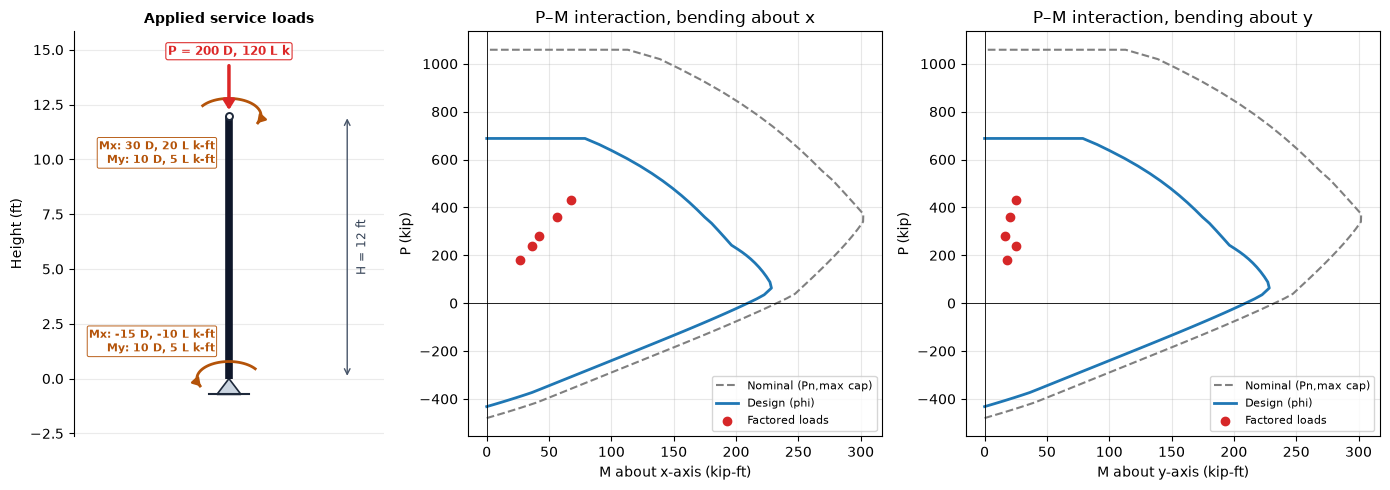

In [7]:
#@title 6. Applied loads and P–M interaction diagram
fig = concrete_column.plot(out)

In [8]:
#@title 7. Save report as HTML (optional)
save_report = False  #@param {type:"boolean"}
if save_report:
    path = out["report"].save_html("concrete_column.html")
    print("saved", path)
    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        pass